# Análisis de ventas con Python y Pandas
### Masterclass Data Analytics con Python — Academia MC

En este notebook vamos a transformar un archivo de ventas en información útil para decidir.

**Antes de calcular nada, vamos a revisar:**
- Qué representa cada fila
- Qué período estamos mirando
- Si hay información incompleta

Vamos a usar **Google Colab** para ejecutar Python desde el navegador, y **Pandas** para trabajar con los datos en forma de tabla.

In [1]:
# Si estás corriendo esto en Colab, subí el archivo ventas.csv a la sesión
# (ícono de carpeta a la izquierda → subir archivo) antes de ejecutar esta celda.

import pandas as pd
import matplotlib.pyplot as plt

# Si ventas.csv está en la misma carpeta (corriendo local) lo usamos;
# si no (por ejemplo en Google Colab), lo bajamos directo de GitHub.
import os
URL_CSV = "https://raw.githubusercontent.com/Academia-Mariana-Casella/masterclass-data-analytics/main/ventas.csv"
ventas = pd.read_csv("ventas.csv" if os.path.exists("ventas.csv") else URL_CSV)
ventas.head()

,id_venta,fecha,canal,categoria,monto,vendedor
0,V01427,02/09/2025,Local,Calzado,10100.0,Lucía R.
1,V00209,02/09/2025,Local,Calzado,4500.0,Sofía G.
2,V00822,02/09/2025,Online,Calzado,16100.0,Sofía G.
3,V00073,03/09/2025,Local,Indumentaria,18900.0,Martín P.
4,V01516,03/09/2025,Local,Calzado,11800.0,Martín P.


## 1. Entender el archivo

Antes de calcular, miramos qué columnas tiene y qué significa cada registro.

**Cada fila de este archivo representa una venta (un ticket) completo** — no un producto dentro de un pedido.

In [2]:
# Cuántas filas y columnas tenemos, y qué tipo de dato es cada columna
print(f"Filas: {len(ventas)}")
print(f"Columnas: {list(ventas.columns)}")
ventas.dtypes

Filas: 1850
Columnas: ['id_venta', 'fecha', 'canal', 'categoria', 'monto', 'vendedor']


id_venta         str
fecha            str
canal            str
categoria        str
monto        float64
vendedor         str
dtype: object

In [3]:
# ¿Qué período cubre el archivo? Ojo: 'fecha' todavía es texto, no fecha.
print("Fecha más antigua (como texto):", ventas['fecha'].min())
print("Fecha más reciente (como texto):", ventas['fecha'].max())

Fecha más antigua (como texto): 01/01/2026
Fecha más reciente (como texto): 31/12/2025


## 2. Convertir la fecha

Para agrupar las ventas por mes, Python tiene que **reconocer esta columna como una fecha**, no como texto.

In [4]:
ventas['fecha'] = pd.to_datetime(ventas['fecha'], format="%d/%m/%Y")

print("Período cubierto:", ventas['fecha'].min().date(), "a", ventas['fecha'].max().date())
ventas.dtypes

Período cubierto: 2025-09-02 a 2026-10-21


id_venta                str
fecha        datetime64[us]
canal                   str
categoria               str
monto               float64
vendedor                str
dtype: object

## 3. Revisar los montos faltantes

Si falta el monto de una venta, ¿lo contamos como cero? ¿Lo dejamos afuera? ¿Buscamos el dato?

**Esa decisión cambia cómo interpretamos el resultado.** En este ejemplo vamos a **separarlos del cálculo** y dejar registrado cuántos son — no vamos a asumir que una venta sin monto vale cero.

In [5]:
faltantes = ventas['monto'].isna().sum()
total_filas = len(ventas)

print(f"Ventas sin monto registrado: {faltantes} de {total_filas} ({faltantes/total_filas*100:.1f}%)")
print()
print("Estas filas quedan fuera de los cálculos de monto, pero las dejamos")
print("documentadas: son datos que faltan, no ventas de $0.")

ventas_con_monto = ventas.dropna(subset=['monto']).copy()

Ventas sin monto registrado: 74 de 1850 (4.0%)

Estas filas quedan fuera de los cálculos de monto, pero las dejamos
documentadas: son datos que faltan, no ventas de $0.


## 4. Agrupar las ventas por mes

Ahora sumamos los montos de cada mes y los mostramos en un gráfico.

> **Nota para la clase:** antes de interpretar, preguntar al público — *"¿Qué les llama la atención? ¿Qué mes aparece más alto?"*

In [6]:
ventas_con_monto['mes'] = ventas_con_monto['fecha'].dt.to_period('M')

ventas_por_mes = ventas_con_monto.groupby('mes')['monto'].sum()
ventas_por_mes

mes
2025-09    1806500.0
2025-10    2219100.0
2025-11    1531700.0
2025-12    3636100.0
2026-01     786000.0
2026-02    1424900.0
2026-03    1710800.0
2026-04    1631200.0
2026-05    1873100.0
2026-06    1593600.0
2026-07    2571000.0
2026-08    1642400.0
2026-09    1818100.0
2026-10    1120100.0
Freq: M, Name: monto, dtype: float64

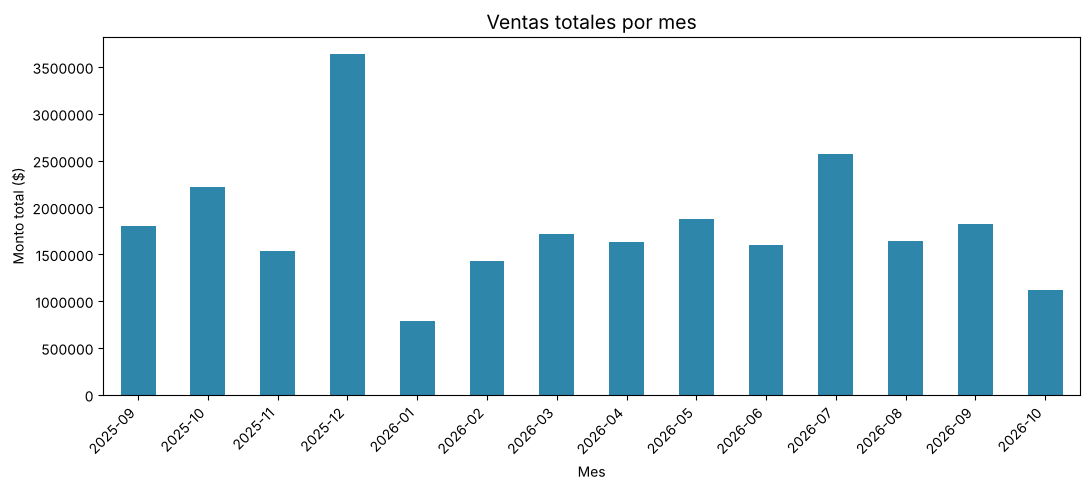

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
ventas_por_mes.plot(kind='bar', ax=ax, color='#2E86AB')

ax.set_title('Ventas totales por mes', fontsize=14)
ax.set_xlabel('Mes')
ax.set_ylabel('Monto total ($)')
ax.ticklabel_format(style='plain', axis='y')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('grafico_ventas_por_mes.png', dpi=150)
plt.show()

## 5. Leer el resultado

Con este gráfico podemos identificar el mes de mayor venta registrada.

**Para explicar *por qué* ocurrió, necesitamos más información**: si hubo una promoción, un cambio de precios, o más operaciones ese mes.

Y si vamos a comparar meses, también tenemos que comprobar que estamos comparando **períodos completos** (por ejemplo, octubre de este año todavía no terminó).

In [8]:
mes_pico = ventas_por_mes.idxmax()
monto_pico = ventas_por_mes.max()

print(f"Mes de mayor venta registrada: {mes_pico}  (${monto_pico:,.0f})")

# Chequeo de períodos completos: ¿cuántos días de cada mes están representados?
dias_por_mes = ventas_con_monto.groupby('mes')['fecha'].apply(lambda x: x.dt.day.max())
print()
print("Último día con datos, por mes (para detectar meses incompletos):")
print(dias_por_mes)

Mes de mayor venta registrada: 2025-12  ($3,636,100)

Último día con datos, por mes (para detectar meses incompletos):
mes
2025-09    30
2025-10    31
2025-11    29
2025-12    31
2026-01    31
2026-02    28
2026-03    31
2026-04    30
2026-05    31
2026-06    30
2026-07    31
2026-08    31
2026-09    30
2026-10    21
Freq: M, Name: fecha, dtype: int32


---
### Para seguir en vivo
- **Parte C** retoma este mismo resultado (ventas por mes) resuelto con una consulta SQL — ver `analisis_sql.sql`.
- **Parte D** usa estos mismos indicadores para armar un mini reporte y mostrar una demo de IA — ver `mini_reporte_ia.ipynb`.